# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: TC5061.10 – Operaciones de Aprendizaje Automático (MLOps)**

**Tecnológico de Monterrey**

**Profesor titular:** Dr. Iván Reyes-Amezcua

**Profesor tutor:** Yetnalezi Quintas Ruiz

**Profesor tutor:** Hesus García Cobos

**Actividad:** Dataset - Notebook individual

**Fecha de entrega:** [04/10/2026]

---

### **Estudiante**

| Nombre | Matrícula |
|---|---|
| Mariely Toribio Rodríguez | A01797848 |

---

> **Nota (actividad MLflow):** este notebook se conserva **solo para la exploración de datos (EDA)**.
> La limpieza, el preprocesamiento, el entrenamiento, la evaluación y el registro en MLflow están en el paquete `attrition/` del proyecto (ver `README.md`).


In [ ]:
# Importación de librerías (solo exploración de datos)
import kagglehub
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Importar la función de distribución normal de scipy.stats para añadir a los gráficos.
from scipy.stats import norm



# **1. Carga y descripción del dataset**

La siguiente actividad se basa en los datos del archivo *"WA_Fn-UseC_-HR-Employee-Attrition.csv"* que se encuentra en la siguiente liga de **Kaggle**: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset, llamada *"IBM HR Analytics Employee Attrition & Performance"*.

Este es un conjunto de datos ficticios creado por científicos de datos de IBM para evaluar los factores que influyen en la rotación de personal por desgaste, o *employee attrition*, que ocurre cuando un empleado deja una organización por cualquier motivo y no es reemplazado durante un período prolongado o, en algunos casos, nunca. Esto suele provocar una disminución en el tamaño de la fuerza laboral de una organización o de un departamento, ya que los puestos no se cubren cuando los empleados se van (Instep, s.f.).

El dataset contiene 1,470 registros con 35 variables. De estas variables existe una objetivo, llamada `Attrition`, con posibles salidas de **Sí** o **No** que nos servirán para nuestro modelo. A continuación, se describen las variables que posee el dataset, sus tipos y significado. Las variables han sido previamente clasificadas en la fuente principal de **Kaggle**:

**a)   Variables numéricas:**
   * **Número de variables:** 17
   * **Nombre de las variables:**
       * Age: Edad del empleado en años.
       * DailyRate: Tarifa salarial diaria.
       * DistanceFromHome: Distancia entre el domicilio del empleado y el lugar de trabajo.
       * HourlyRate: Tarifa salarial por hora.
       * MonthlyIncome: Salario mensual del empleado.
       * MonthlyRate: Tarifa de facturación mensual.
       * NumCompaniesWorked: Número de empresas en las que ha trabajado previamente.
       * PercentSalaryHike: Porcentaje de aumento salarial entre dos años (2017 y 2018).
       * TotalWorkingYears: Total de años trabajados en todos los empleos.
       * TrainingTimesLastYear: Horas dedicadas a formación el último año.
       * YearsAtCompany: Total de años en la empresa actual.
       * YearsInCurrentRole: Número de años en el puesto actual.
       * YearsSinceLastPromotion: Número de años desde el último ascenso.
       * YearsWithCurrManager: Número de años trabajando con el jefe actual.
       * EmployeeCount: Número total de empleados (valor constante).
       * EmployeeNumber: Identificador único de cada empleado.
       * StandardHours: Horas estándar trabajadas por semana (valor constante).

**b)   Variables ordinales:**
   * **Número de variables:** 9
   * **Nombre de las variables:**
       * Education: Nivel educativo del empleado (1 Below College, 2 College, 3 Bachelor, 4 Master, 5 Doctor)
       * EnvironmentSatisfaction: Nivel de satisfacción con el entorno de trabajo (1 Low, 2 Medium, 3 High, 4 Very High)
       * JobInvolvement: Nivel de implicación en el trabajo (1 Low, 2 Medium, 3 High, 4 Very High)
       * JobSatisfaction: Nivel de satisfacción con el trabajo (1 Low, 2 Medium, 3 High, 4 Very High)
       * PerformanceRating: Valoración del desempeño del empleado (1 Low, 2 Good, 3 Excellent, 4 Outstanding)
       * RelationshipSatisfaction: Nivel de satisfacción con las relaciones en el trabajo (1 Low, 2 Medium, 3 High, 4 Very High)
       * WorkLifeBalance: Nivel de satisfacción con el equilibrio entre vida laboral y personal (1 Bad, 2 Good, 3 Better, 4 Best)
       * StockOptionLevel: Nivel de opciones sobre acciones que posee el empleado (0, 1, 2, 3)
       * JobLevel: Nivel del puesto del empleado en la jerarquía de la empresa (1, 2, 3, 4, 5)

**c)   Variables binarias:**
   * **Número de variables:** 4
   * **Nombre de las variables:** 
       * Attrition: Si el empleado abandonó la empresa (Yes, No), **variable de salida**
       * OverTime: Si el empleado hace horas extra (Yes, No)
       * Gender: Género del empleado (Male, Female)
       * Over18: Si el empleado es mayor de 18 años (Yes, No)

**d)   Variables nominales:**
   * **Número de variables:** 5
   * **Nombre de las variables:**
       * BusinessTravel: Frecuencia de viajes de negocios (Travel_Rarely, Travel_Frequently, Non-Travel)
       * Department: Departamento del empleado (Research & Development, Sales, Human Resources)
       * EducationField: Campo de estudios (Life Sciences, Medical, Marketing, Technical Degree, Other, Human Resources)
       * JobRole: Puesto específico del empleado (Sales Executive, Research Scientist, Laboratory Technician, Manufacturing Director, etc)
       * MaritalStatus: Estado civil del empleado (Married, Single, Divorced)

Cargamos el archivo como un DataFrame de Pandas y hacemos uso del método `describe` con el argumento `include = 'all'` para desplegar información de todas las variables, numéricas y categóricas.

In [2]:
ruta = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
data = pd.read_csv(os.path.join(ruta, "WA_Fn-UseC_-HR-Employee-Attrition.csv"))

print("Tamaño del DataFrame:", data.shape)
data.describe(include = "all").T

Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


# **2. Análisis exploratorio (EDA): inspección de los datos**

In [3]:
# Definimos el tipo de variables según el orden del punto anterior. En el dataset original las 
# ordinales vienen como int64, así que select_dtypes() las mezclaría con las numéricas.

num_cols = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome", "MonthlyRate",
            "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear",
            "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager", 
            "EmployeeCount", "EmployeeNumber", "StandardHours"]
 
ord_cols = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction",
            "PerformanceRating", "RelationshipSatisfaction", "WorkLifeBalance",
            "StockOptionLevel", "JobLevel"]
 
bin_cols = ["Attrition", "OverTime", "Gender", "Over18"]
 
nom_cols = ["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus"]
 
cat_cols = ord_cols + bin_cols + nom_cols


In [4]:
# Para una mejor comprensión de los resultados en Jupyter Notebook, daremos formato a los títulos.
from IPython.display import display, Markdown

# Veamos la información general del DataFrame.
display(Markdown('## **Información general del DataFrame**')) # Título en Markdown
display(data.info())

# Veamos las primeras y últimas 5 filas del DataFrame para tener una idea general de los datos.
display(Markdown('## **Primeras y últimas 5 filas del DataFrame**')) # Título en Markdown
display(data.head(5).tail(5))

# Busquemos registros duplicados en el DataFrame.
display(Markdown('## **Registros duplicados en el DataFrame**')) # Título en Markdown
display(data.duplicated().sum())

# Busquemos valores nulos en el DataFrame.
display(Markdown('## **Valores nulos en el DataFrame**')) # Título en Markdown
display(data.isnull().sum())

# Veamos cuántos valores únicos tiene cada variable en el DataFrame.
display(Markdown('## **Número de valores únicos por variable**')) # Título en Markdown
display(data.nunique().sort_values())

# Revisaremos las características de las variables numéricas y categóricas por separado.
# Inicialmente, veamos las variables numéricas.

# VARIABLES NUMÉRICAS
# -------------------------------------------------------------------------------------------------------------------------
# Calculamos las estadísticas descriptivas para las variables numéricas.
stats_num = data.describe().T
# Desplegamos el resultado.
display(Markdown('## **Estadísticas descriptivas para variables numéricas**')) # Título en Markdown
display(stats_num)


# VARIABLES CATEGÓRICAS
# -------------------------------------------------------------------------------------------------------------------------
# Calculamos las estadísticas descriptivas para las variables categóricas.
display(Markdown('## **Estadísticas descriptivas para variables categóricas**')) # Título en Markdown
display(data.describe(exclude=[int, float]).T)
# Desplegamos las frecuencias de las columnas categóricas.
display(Markdown('## **Frecuencias de las variables categóricas**')) # Título en Markdown
# Recorremos las columnas categóricas para mostrar sus frecuencias.
for col in cat_cols:
    print(f'\nVariable: {col}')
    # Mostramos los valores únicos por variable.
    print('Unique values')
    print(data[col].unique())
    # Generamos la frecuencia absoluta y relativa.
    freq_absolut = data[col].value_counts()
    freq_relative = data[col].value_counts(normalize=True) * 100
    freq_table = pd.concat([freq_absolut, freq_relative], axis=1)
    # Imprimimos la frecuencia absoluta.
    print('Frecuency')
    display(freq_table)

## **Información general del DataFrame**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

None

## **Primeras y últimas 5 filas del DataFrame**

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


...

,count,proportion
EducationField,,
Life Sciences,606,41.224490
Medical,464,31.564626
Marketing,159,10.816327
Technical Degree,132,8.979592
Other,82,5.578231
Human Resources,27,1.836735



Variable: JobRole
Unique values
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']
Frecuency


,count,proportion
JobRole,,
Sales Executive,326,22.176871
Research Scientist,292,19.863946
Laboratory Technician,259,17.619048
Manufacturing Director,145,9.863946
Healthcare Representative,131,8.911565
Manager,102,6.938776
Sales Representative,83,5.646259
Research Director,80,5.442177
Human Resources,52,3.537415



Variable: MaritalStatus
Unique values
['Single' 'Married' 'Divorced']
Frecuency


,count,proportion
MaritalStatus,,
Married,673,45.782313
Single,470,31.972789
Divorced,327,22.244898


A continuación, realizaremos gráficos para ver la distribución de las variables y explorar relaciones.

## **Estadísticas descriptivas para variables numéricas**

,count,mean,std,min,25%,50%,75%,max,kurt,skew,skew_class,kurt_class
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0,-0.404145,0.413286,Aprox. simétrica,Aprox. mesocúrtica
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0,-1.203823,-0.003519,Aprox. simétrica,Platicúrtica
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0,-0.224833,0.958118,Ligera asimetría,Aprox. mesocúrtica
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0,-1.196398,-0.032311,Aprox. simétrica,Platicúrtica
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.00,4919.0,8379.00,19999.0,1.005233,1.369817,Asimétrica,Leptocúrtica
MonthlyRate,1470.0,14313.103401,7117.786044,2094.0,8047.00,14235.5,20461.50,26999.0,-1.214956,0.018578,Aprox. simétrica,Platicúrtica
NumCompaniesWorked,1470.0,2.693197,2.498009,0.0,1.00,2.0,4.00,9.0,0.010214,1.026471,Asimétrica,Aprox. mesocúrtica
PercentSalaryHike,1470.0,15.209524,3.659938,11.0,12.00,14.0,18.00,25.0,-0.300598,0.821128,Ligera asimetría,Aprox. mesocúrtica
TotalWorkingYears,1470.0,11.279592,7.780782,0.0,6.00,10.0,15.00,40.0,0.918270,1.117172,Asimétrica,Leptocúrtica
TrainingTimesLastYear,1470.0,2.799320,1.289271,0.0,2.00,3.0,3.00,6.0,0.494993,0.553124,Ligera asimetría,Aprox. mesocúrtica


## **Estadísticas descriptivas para variables categóricas**

,count,unique,top,freq
Education,1470,5,3,572
EnvironmentSatisfaction,1470,4,3,453
JobInvolvement,1470,4,3,868
JobSatisfaction,1470,4,4,459
PerformanceRating,1470,2,3,1244
RelationshipSatisfaction,1470,4,3,459
WorkLifeBalance,1470,4,3,893
StockOptionLevel,1470,4,0,631
JobLevel,1470,5,1,543
Attrition,1470,2,No,1233


## **Histogramas de variables numéricas**

C:\Users\Mariely\AppData\Local\Temp\ipykernel_11216\2238097592.py:57: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(x=data[col], ax=ax, lw=2, label="KDE", color="darkblue")
c:\Users\Mariely\Documents\Tec de Monterrey\10. MLOPs\attrition\.venv\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2065: RuntimeWarning: invalid value encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
C:\Users\Mariely\AppData\Local\Temp\ipykernel_11216\2238097592.py:57: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(x=data[col], ax=ax, lw=2, label="KDE", color="darkblue")
c:\Users\Mariely\Documents\Tec de Monterrey\10. MLOPs\attrition\.venv\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2065: RuntimeWarning: invalid value encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)


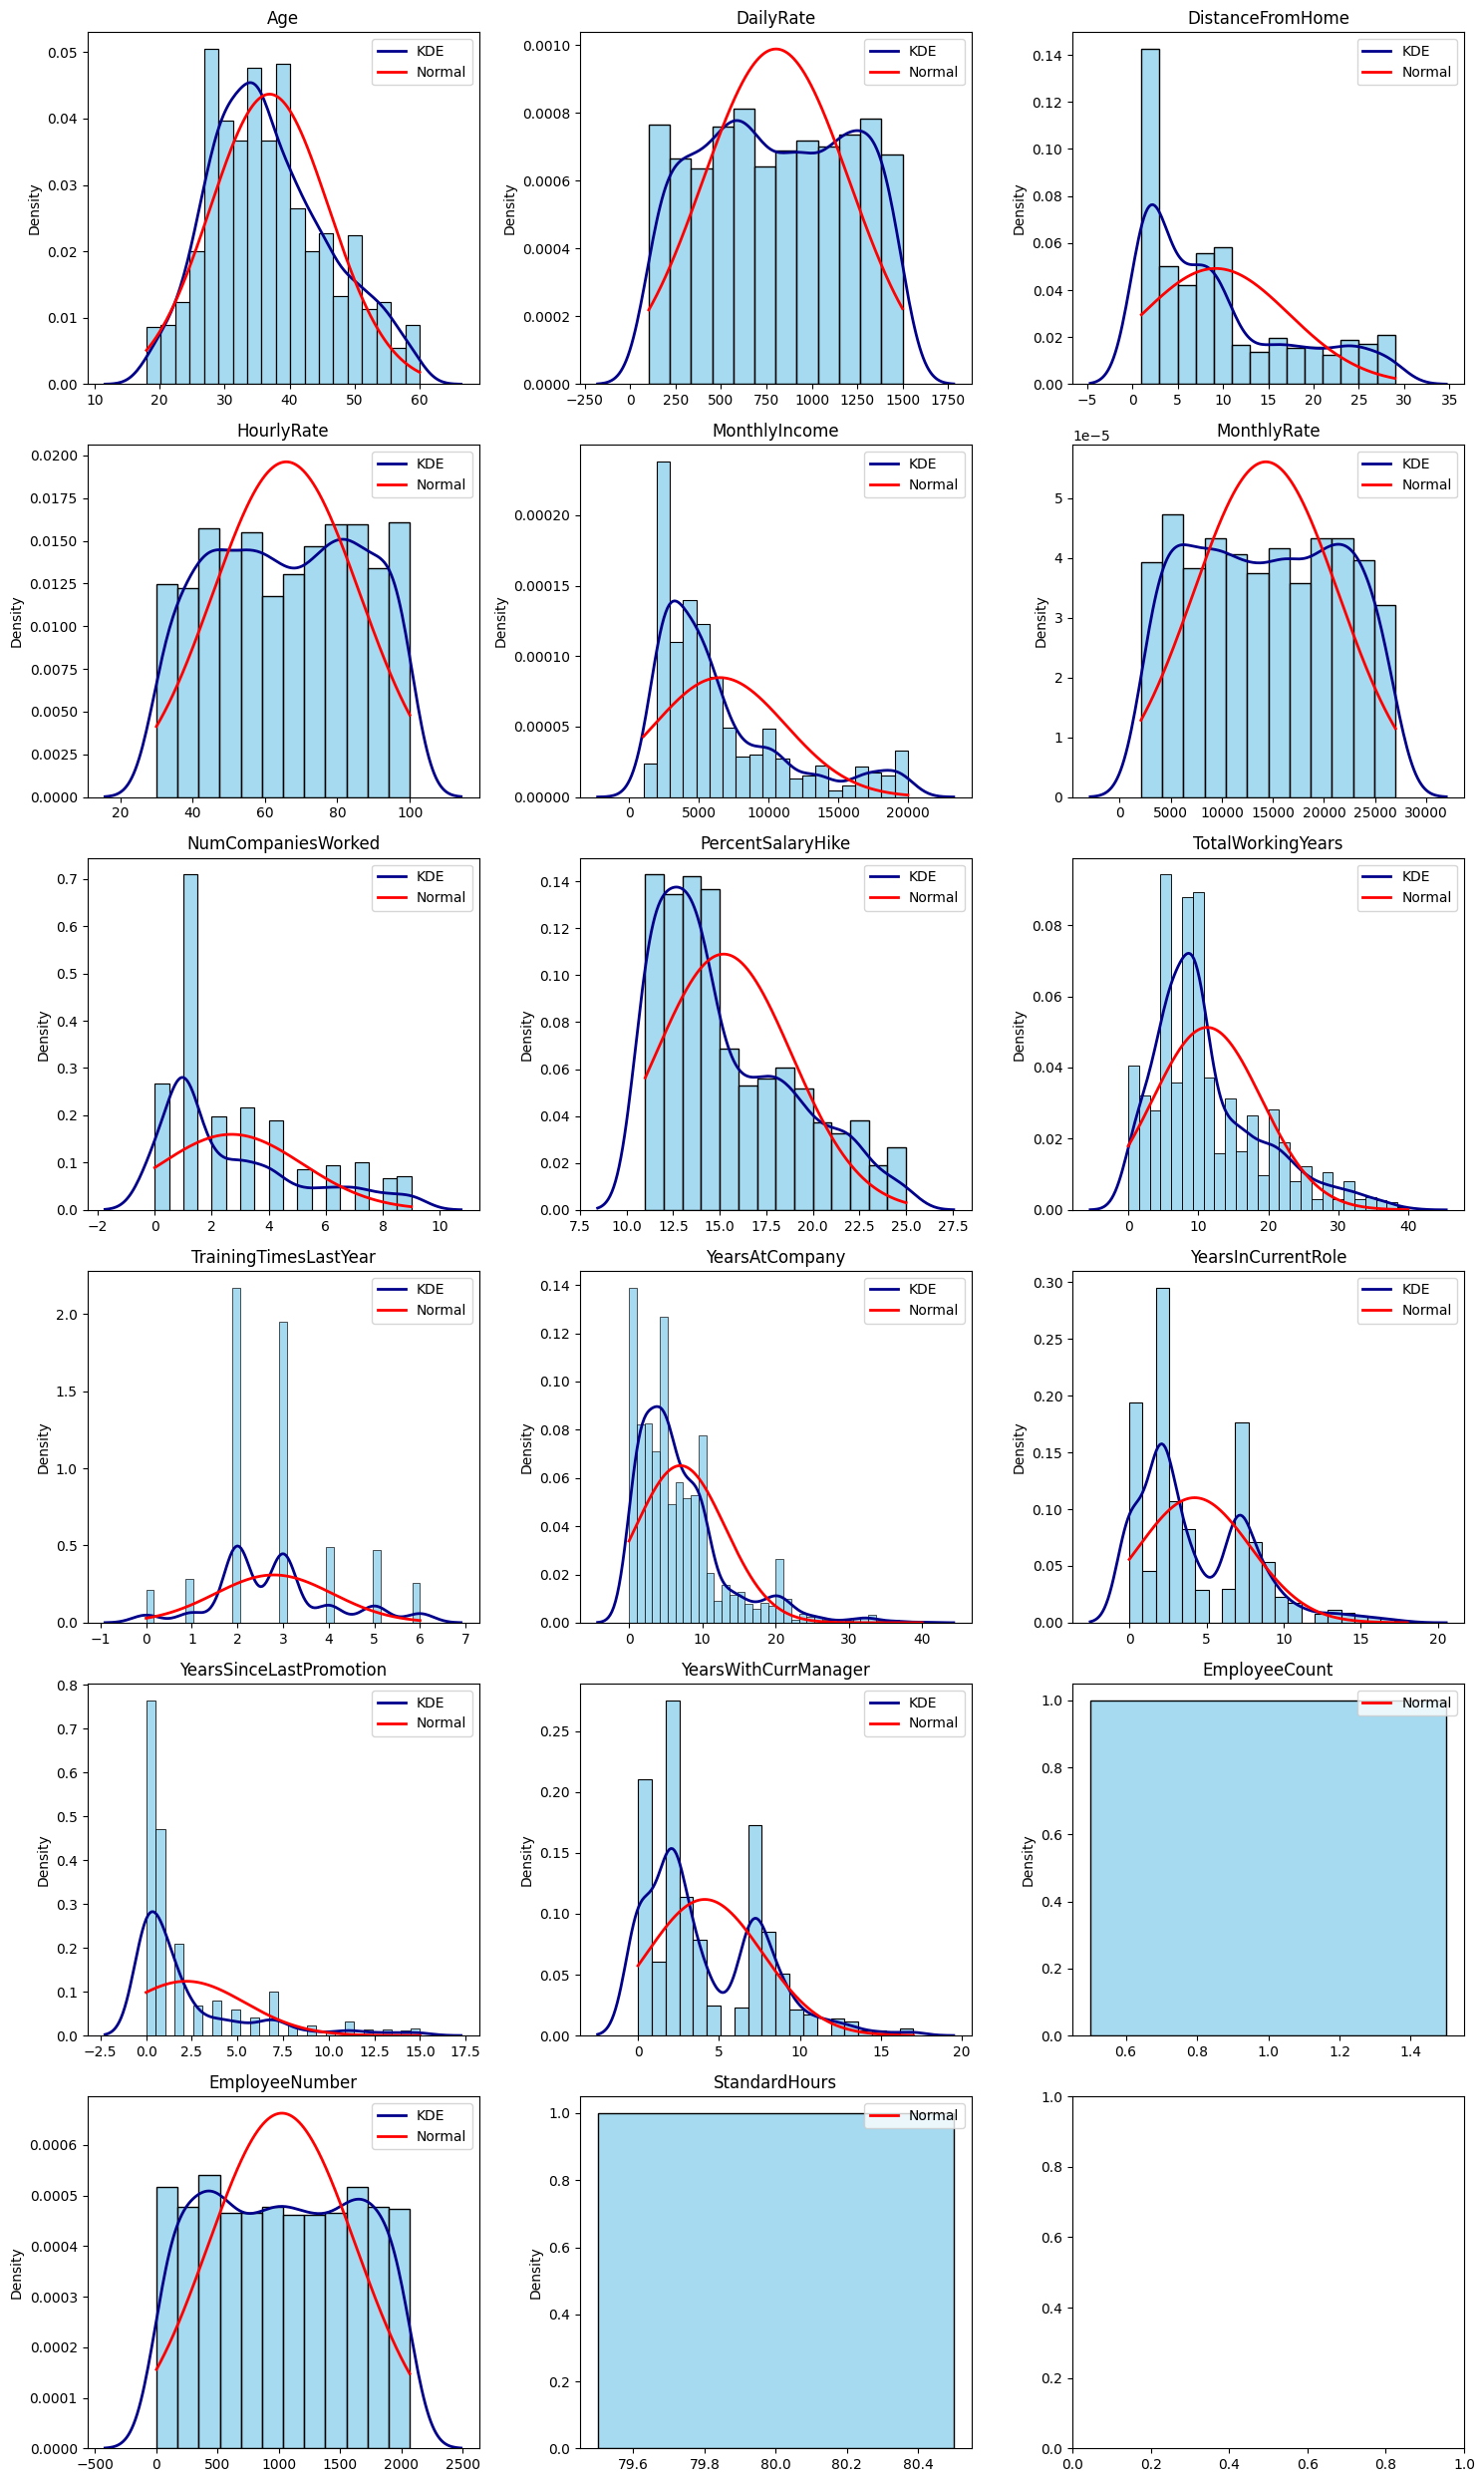

## **Gráficos de barras para variables categóricas**

C:\Users\Mariely\AppData\Local\Temp\ipykernel_11216\2238097592.py:80: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.1)
C:\Users\Mariely\AppData\Local\Temp\ipykernel_11216\2238097592.py:94: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


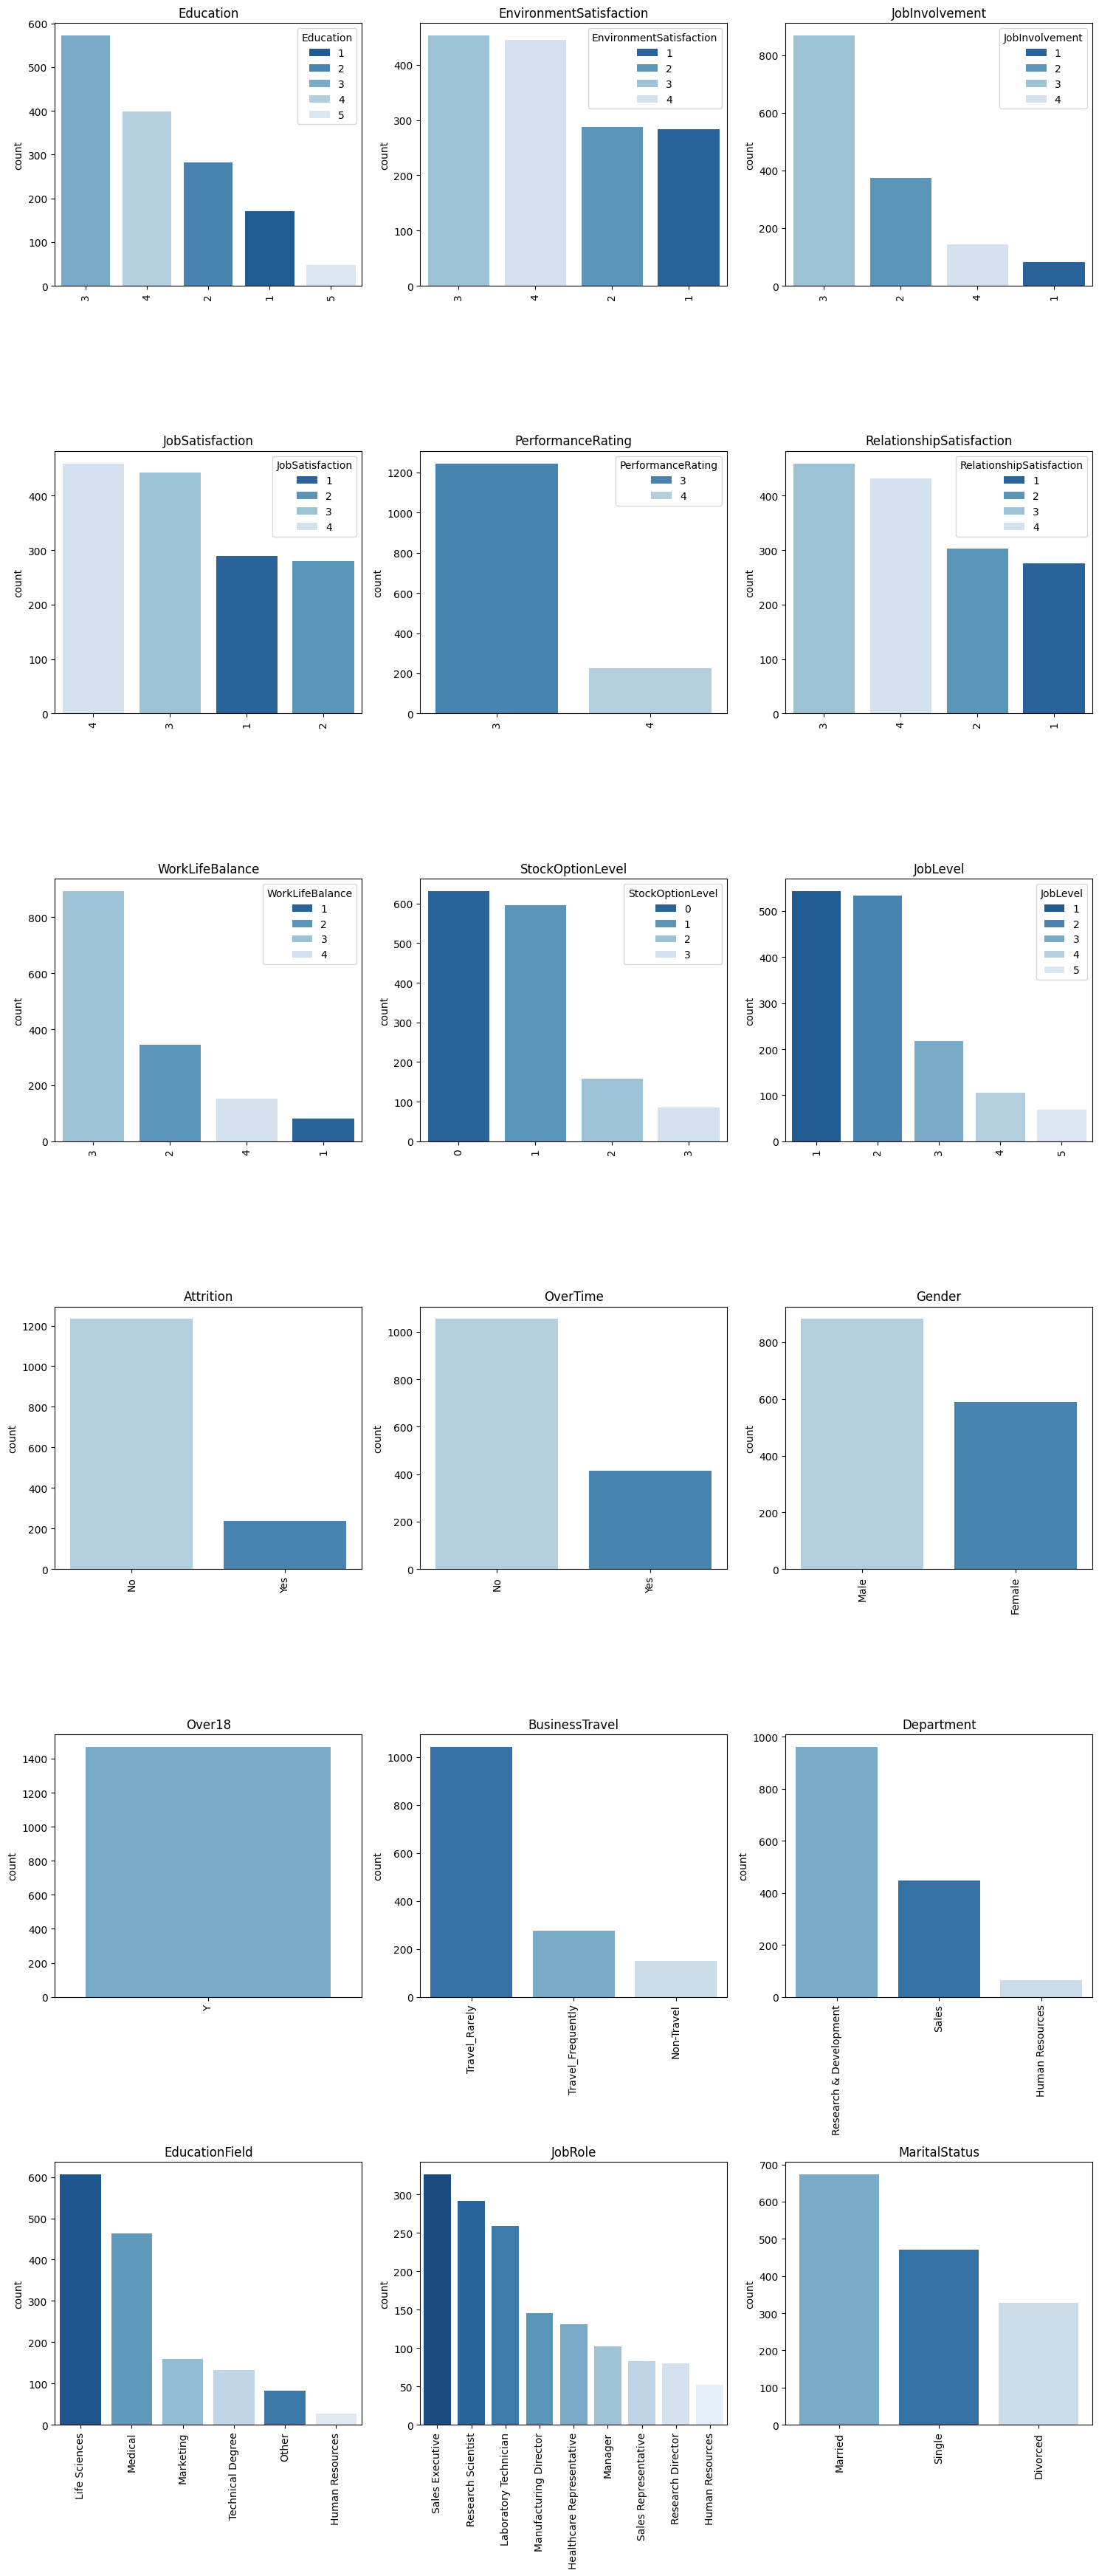

## **Matriz de correlación para variables numéricas**

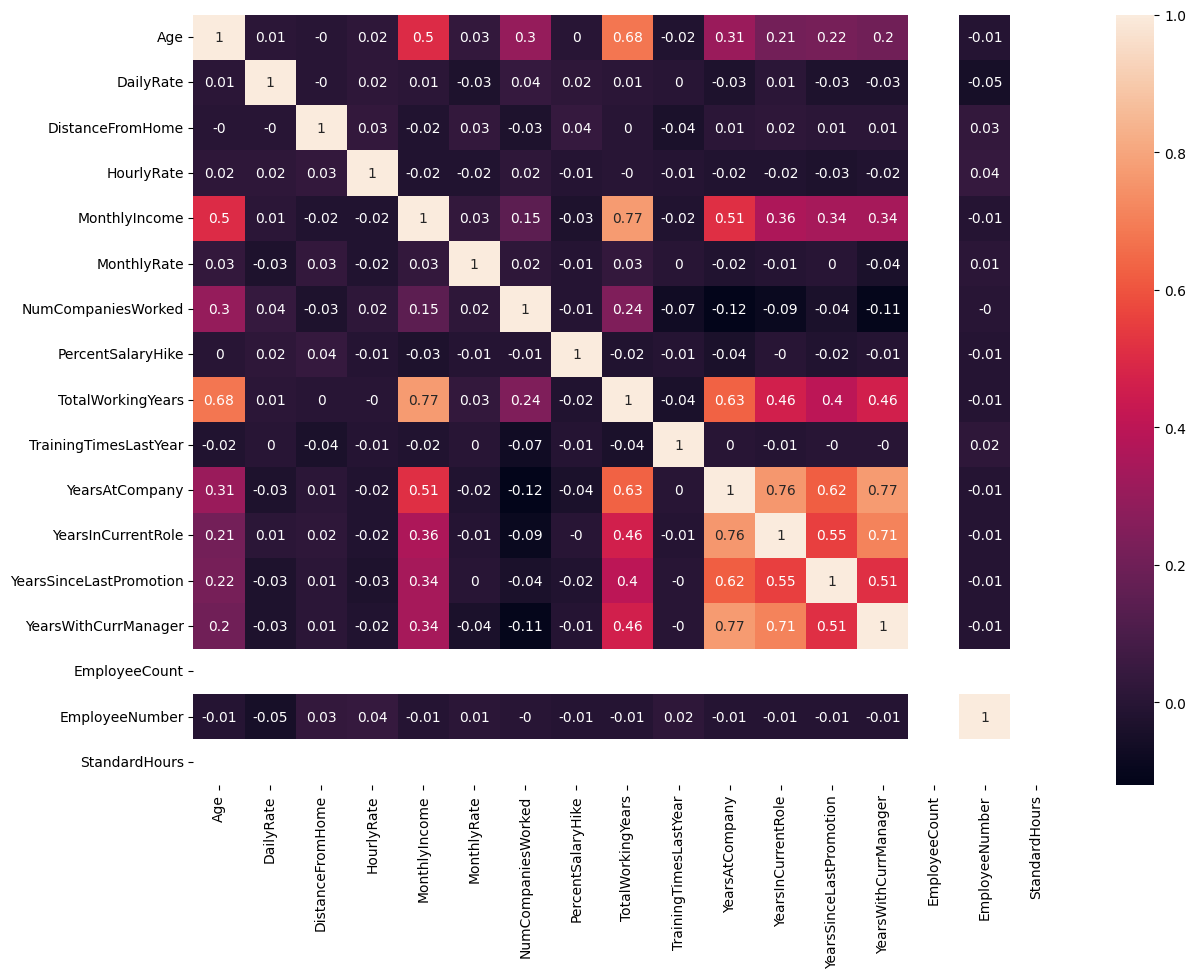

## **Boxplots de variables numéricas**

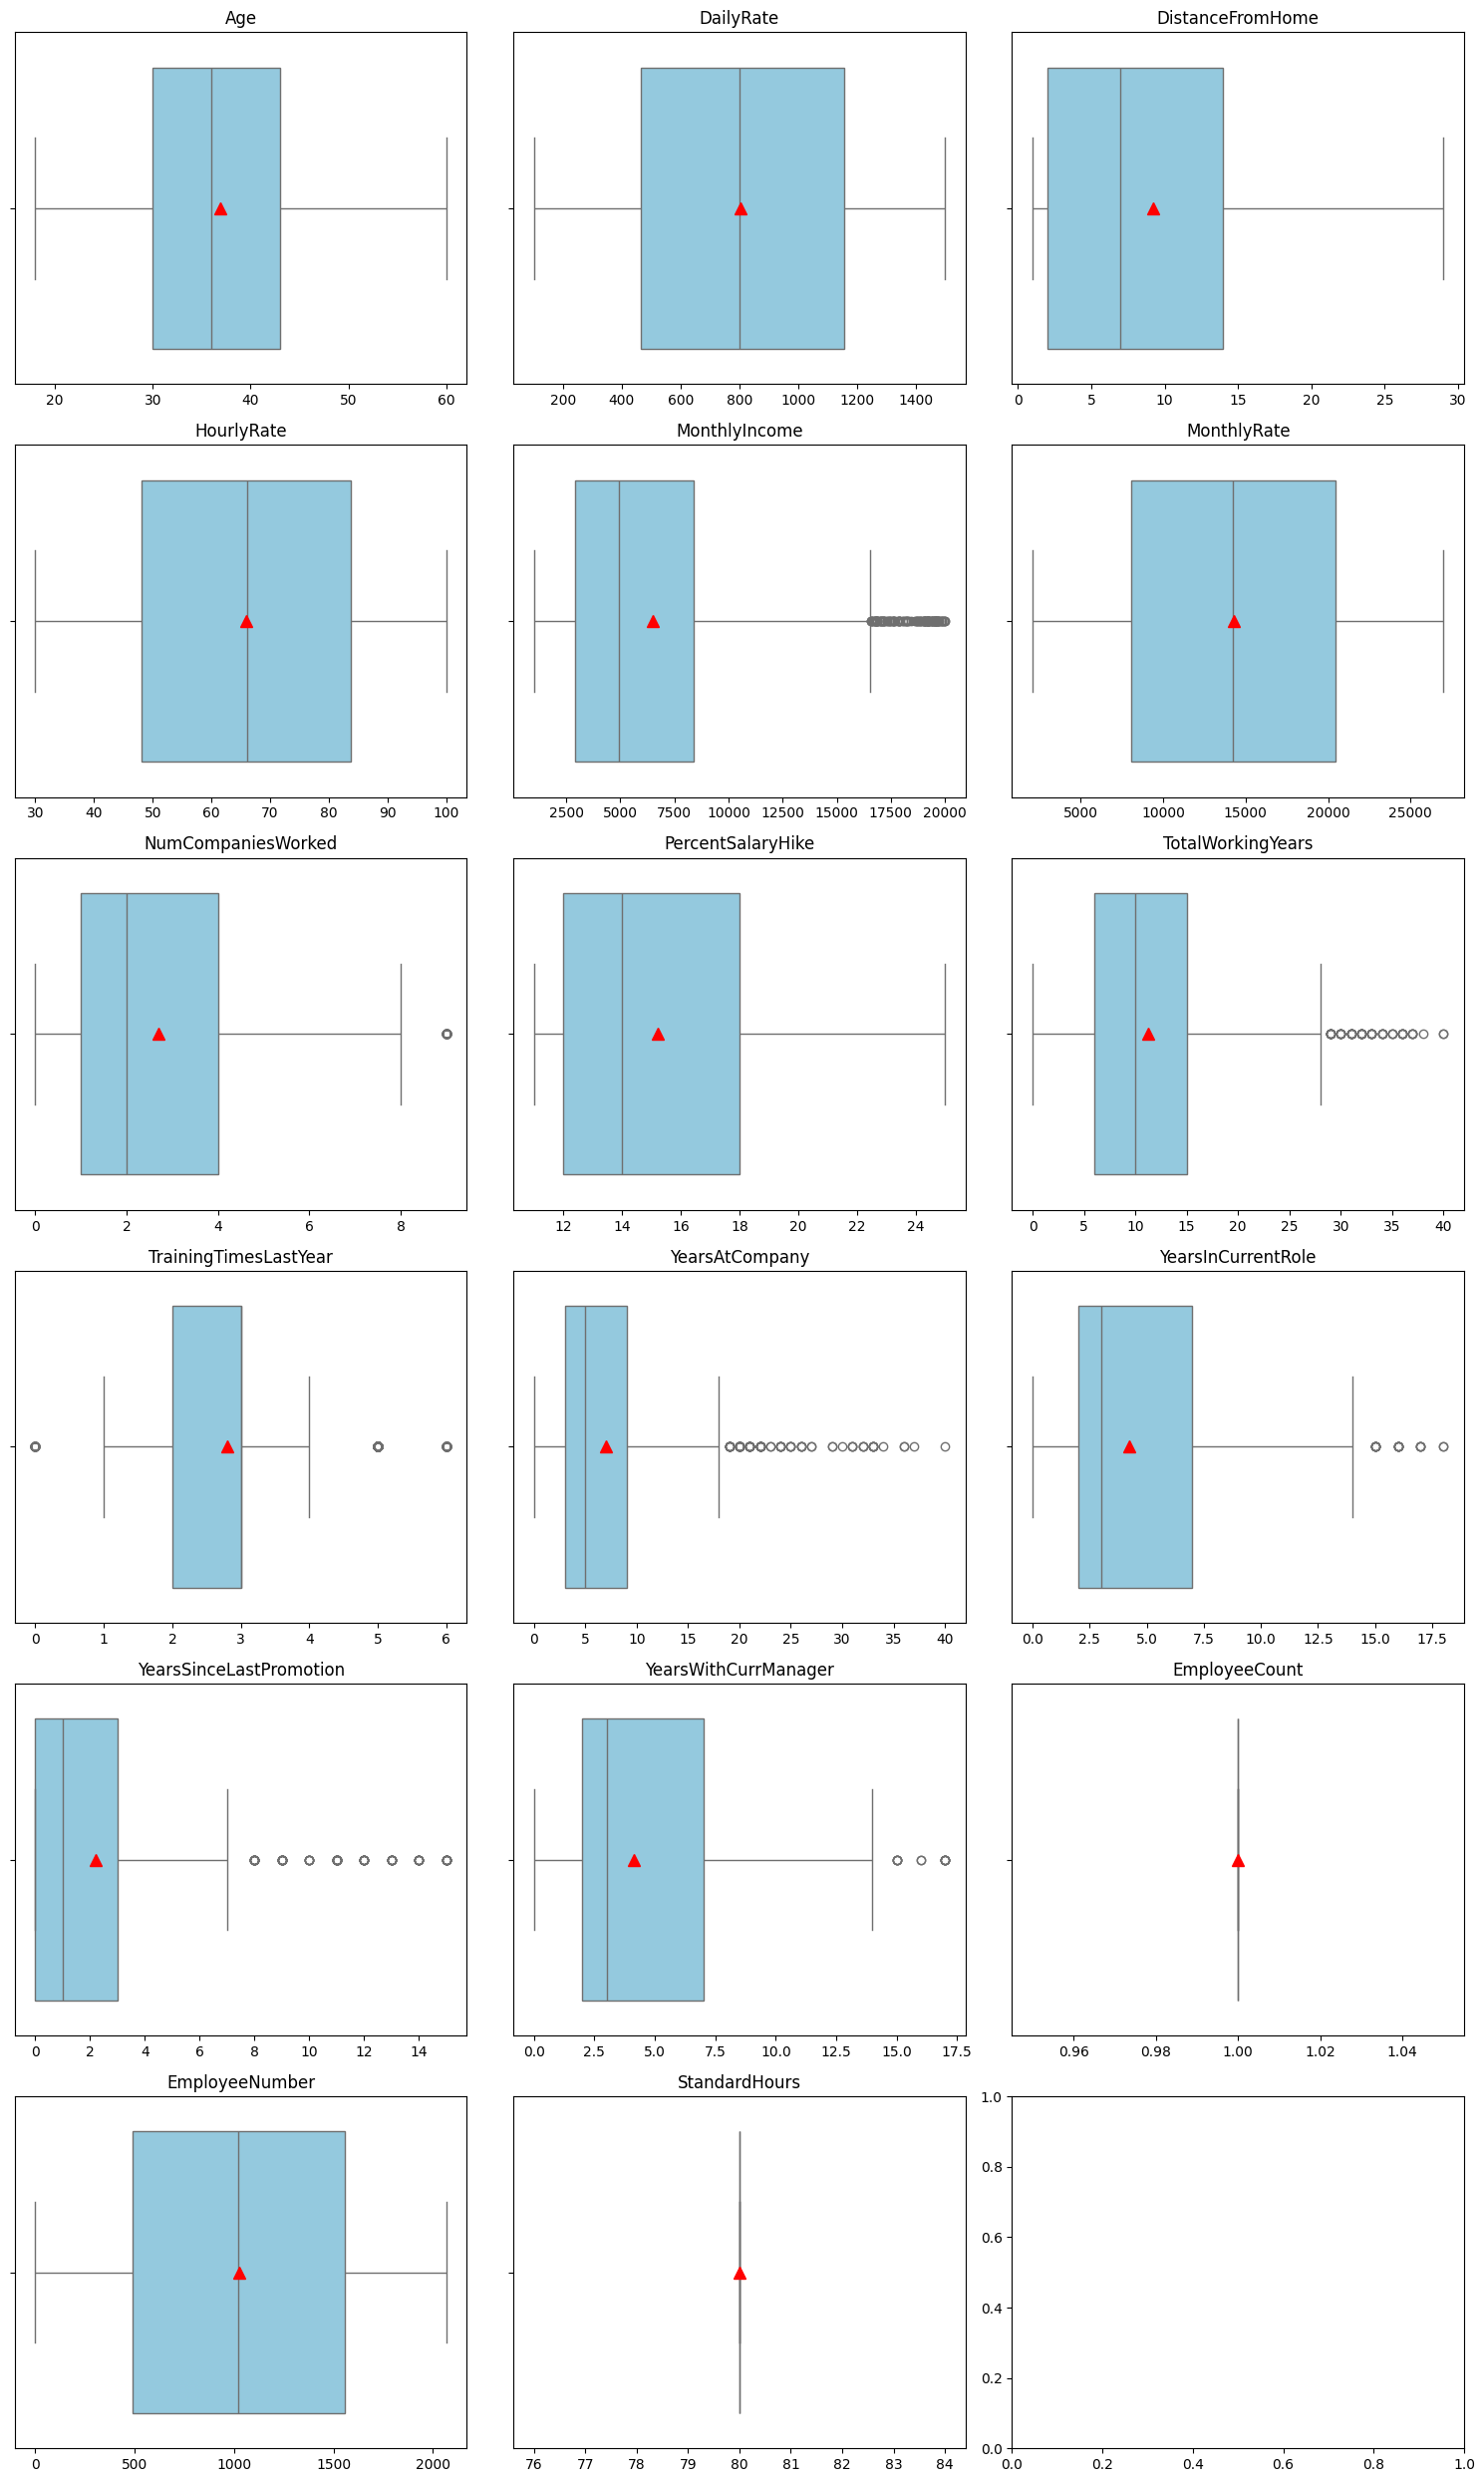

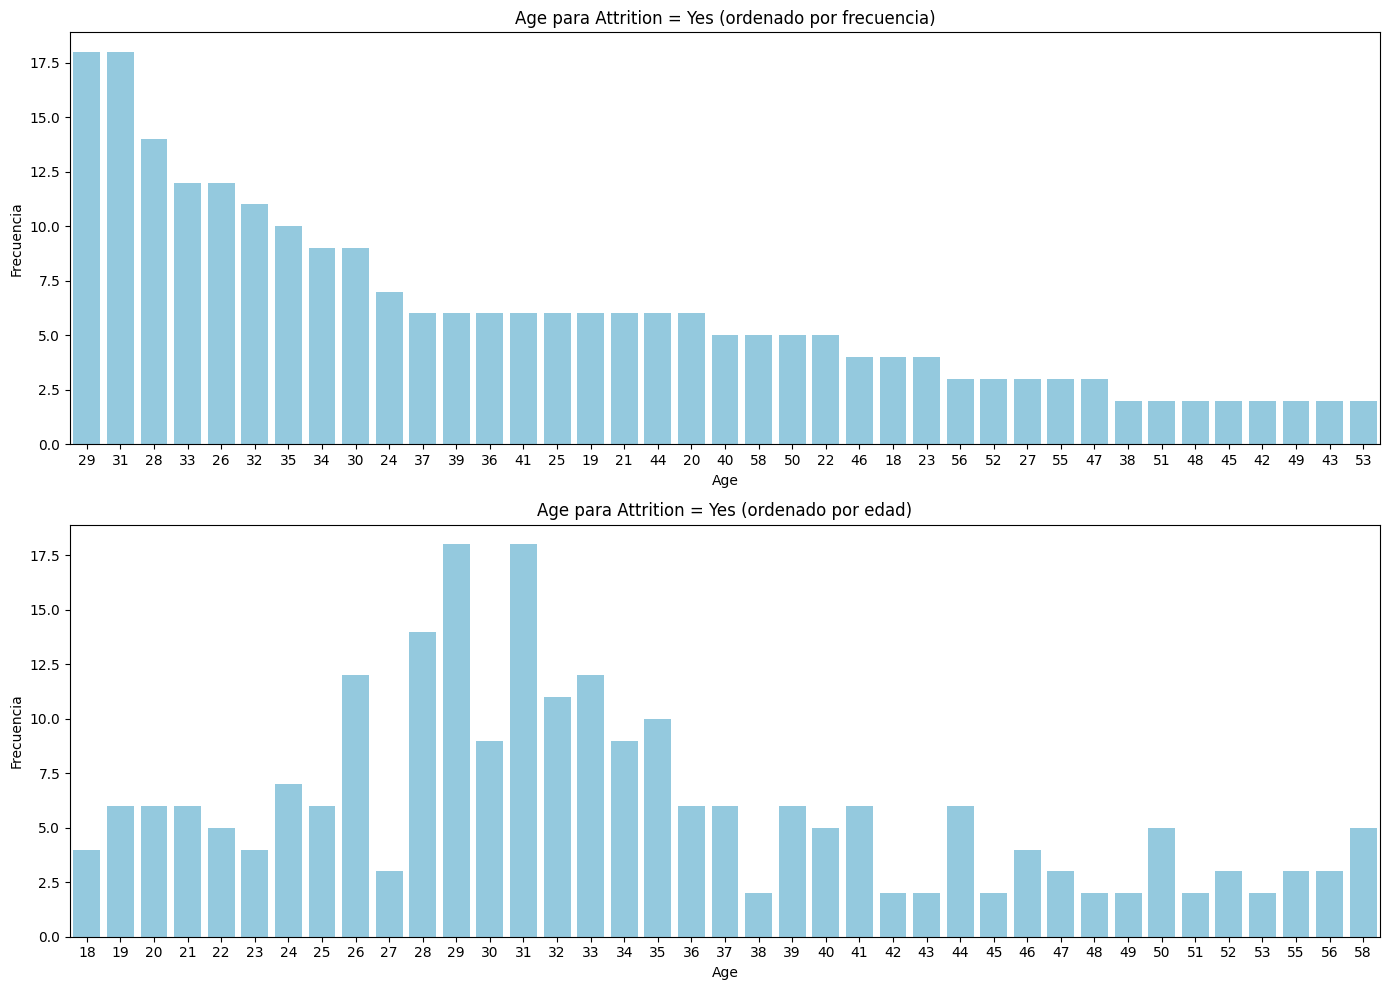

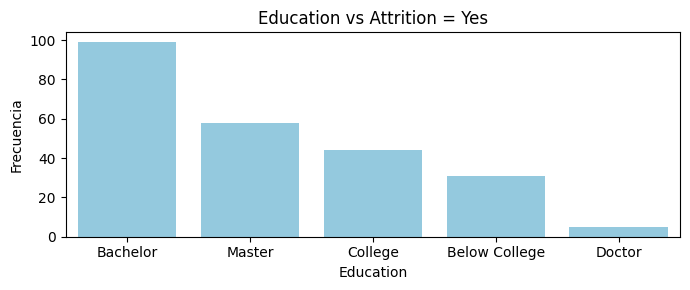

In [5]:
# ESTADÍSTICAS DESCRIPTIVAS
# -------------------------------------------------------------------------------------------------------------------------
# Calculamos las estadísticas descriptivas para las variables numéricas.

# Función para clasificar el sesgo.
def skew_classification(skew):
    if -0.5 <= skew <= 0.5:     return "Aprox. simétrica"
    elif (-1 <= skew < -0.5) or (0.5 < skew <= 1):  return "Ligera asimetría"
    else:   return "Asimétrica"

# Función para clasificar la curtosis.
def kurt_classification(kurt):
    if -0.5 <= kurt <= 0.5:     return "Aprox. mesocúrtica"
    elif kurt < -0.5:   return "Platicúrtica"
    else:   return "Leptocúrtica"

# Obtener las estadísticas descriptivas para variables númericas.
stats_num = data[num_cols].describe().T

# Adjuntar el sesgo y la curtosis a la tabla.
stats_num["kurt"] = data[num_cols].kurt(numeric_only=True)
stats_num["skew"] = data[num_cols].skew(numeric_only=True)

# Añadir la clasificación del sesgo y la curtosis.
stats_num["skew_class"] = stats_num["skew"].apply(skew_classification)
stats_num["kurt_class"] = stats_num["kurt"].apply(kurt_classification)

# Desplegamos el resultado.
display(Markdown('## **Estadísticas descriptivas para variables numéricas**')) # Título en Markdown
display(stats_num)

# Calculamos las estadísticas descriptivas para las variables categóricas.
display(Markdown('## **Estadísticas descriptivas para variables categóricas**')) # Título en Markdown
# Para este paso convertimos las variables categóricas a tipo "category" para obtener estadísticas más precisas.
display(data[cat_cols].astype("category").describe().T)
# -------------------------------------------------------------------------------------------------------------------------


# HISTOGRAMAS 
# -------------------------------------------------------------------------------------------------------------------------
# Realizamos histogramas para las variables numéricas.
display(Markdown('## **Histogramas de variables numéricas**'))      # Título en Markdown

# Se combinan las plataformas:
# - Matplotlib para crear la matriz de subgráficos y escribir los títulos.
# - Seaborn para dibujar los histogramas.

# Generamos la figura con los subgráficos.
fig, axes = plt.subplots(6, 3, figsize=(15, 25))  # ---> Matplotlib
plt.subplots_adjust(wspace=0.3) # Ajuste del espacio entre subgráficos.
axes = axes.ravel() # Aplanamos la matriz de ejes para facilitar el acceso.

# Generar histogramas para las numéricas.
# Recorremos las columnas numéricas para graficar sus histogramas.
for col, ax in zip(data[num_cols], axes):
    # Graficar la curva KDE para cada variable.
    sns.kdeplot(x=data[col], ax=ax, lw=2, label="KDE", color="darkblue")

    # Agregar el histograma para cada variable.
    sns.histplot(x=data[col], ax=ax, stat="density", color="skyblue")  # ---> Seaborn

    # Graficar la curva de la distribución normal con el uso de scipy.
    x_vals = np.linspace(data[col].min(), data[col].max(), 1000)
    normal_ref = norm.pdf(x_vals, loc=data[col].mean(), scale=data[col].std())
    ax.plot(x_vals, normal_ref, lw=2, label="Normal", color="red")

    # Añadir las leyendas y títulos.
    ax.set(title=f"{col}", xlabel=None)  # ---> Matplotlib
    ax.legend()

plt.tight_layout()
plt.show()


# Realizamos gráficos de barras para las variables categóricas repitiendo
# el mismo procedimiento que para los histogramas.
display(Markdown('## **Gráficos de barras para variables categóricas**'))      # Título en Markdown

fig, axes = plt.subplots(6, 3, figsize=(15, 35), layout="constrained")  # ---> Matplotlib
plt.subplots_adjust(wspace=0.1)
axes = axes.ravel()

for col, ax in zip(data[cat_cols], axes):
    sns.countplot(
        x=data[col], 
        hue=data[col], 
        ax=ax, 
        order=data[col].value_counts().index,
        palette=sns.color_palette("Blues_r", len(data[col].value_counts().index)),
    )  # ---> Seaborn
    ax.set(title=f"{col}", xlabel=None)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.plot()
plt.show()


# MATRIZ DE CORRELACIÓN
# -----------------------------------------------------------------------------------------------------------
display(Markdown('## **Matriz de correlación para variables numéricas**'))      # Título en Markdown
# Dibujar un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
plt.figure(figsize=(14, 10))  # ---> Matplotlib
# Crear el mapa de calor con Seaborn.
sns.heatmap(
    round(data[num_cols].corr(numeric_only=True), 2), annot=True)
plt.show()

# -----------------------------------------------------------------------------------------------------------


# BOXPLOTS
# -----------------------------------------------------------------------------------------------------------
display(Markdown('## **Boxplots de variables numéricas**'))      # Título en Markdown

fig, axes = plt.subplots(6, 3, figsize=(15, 25))  # ---> Matplotlib
plt.subplots_adjust(wspace=0.3)
axes = axes.ravel()

for col, ax in zip(data[num_cols], axes):
    # Agregamos el histograma para cada variable.
    sns.boxplot(x=data[col], 
                ax=ax, 
                color='skyblue', 
                showmeans=True, 
                meanprops={'markerfacecolor':'red', 'markeredgecolor':'red', 'markersize':'8'})  # ---> Seaborn

    # Añadimos las leyendas y títulos.
    ax.set(title=f'{col}', xlabel=None)  # ---> Matplotlib
plt.tight_layout()
plt.show()
# -----------------------------------------------------------------------------------------------------------


# Haremos algunos gráficos de barras para analizar la relación entre las variables edad, educación 
# y la variable objetivo "Attrition".

# Gráfico age-attrition[yes]

# Filtrar solo Attrition = Yes
age_yes = data.loc[data['Attrition'] == 'Yes', 'Age']
# Frecuencia por edad
age_freq = age_yes.value_counts()
# Crear figura con dos subgráficos (uno debajo del otro)
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)

# Gráfico 1: ordenado por frecuencia (descendente)
# Ordenamos la frecuencia de edad en orden descendente
age_freq_desc = age_freq.sort_values(ascending=False)
# Usamos seaborn para crear el gráfico de barras
sns.barplot(
    x=age_freq_desc.index.astype(str), y=age_freq_desc.values, order=age_freq_desc.index.astype(str), ax=axes[0], color='skyblue'
)
# Añadimos títulos y etiquetas
axes[0].set_title('Age para Attrition = Yes (ordenado por frecuencia)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frecuencia')

# Gráfico 2: ordenado por EDAD (ascendente)
age_freq_age = age_freq.sort_index()
# Usamos seaborn para crear el gráfico de barras
sns.barplot(
    x=age_freq_age.index.astype(str), y=age_freq_age.values, order=age_freq_age.index.astype(str), ax=axes[1], color='skyblue'
)
# Añadimos títulos y etiquetas
axes[1].set_title('Age para Attrition = Yes (ordenado por edad)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

# c) Gráfico education-attrition[yes]
# Etiquetas de Kaggle para el nivel de educación
education_labels = {
    1: 'Below College',
    2: 'College',
    3: 'Bachelor',
    4: 'Master',
    5: 'Doctor'
}

# Filtrar Attrition = Yes y mapear etiquetas
edu_yes = data.loc[data['Attrition'] == 'Yes', 'Education'].map(education_labels)
# Frecuencias ordenadas (mayor a menor)
edu_freq = edu_yes.value_counts().sort_values(ascending=False)

# Gráfico con Seaborn
plt.figure(figsize=(7, 3))
sns.barplot(
    x=edu_freq.index, y=edu_freq.values,order=edu_freq.index, color='skyblue'
)
plt.title('Education vs Attrition = Yes')
plt.xlabel('Education')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()





### **2.1. Análisis de los gráficos y estadísticas**

Se detallarán los hallazgos más relevantes de los gráficos y las estadísticas arrojadas, con el fin de justificar las transformaciones recomendadas. 
Debemos tomar en cuenta que en las variables de entrada, no importa cómo se ve la distribución, sino cuánta variabilidad o información aporta. Es por esto que para las variables de entrada estamos analizando rangos, outliers y escalas, sin necesidad de forzar la normalidad de ciertas variables.

* **Valores faltantes:**
  * No existen valores faltantes en el dataset. Sin embargo por buenas prácticas siempre es ideal añadir un imputer en el pipeline previo a una transformación, y más cuando los datos serán utilizados con modelos de Aprendizaje Automático, que no soportan valores nulos. Esto lo tendremos pendiente para aplicarlo en el paso de Pipeline y Column Transformer.
* **Histogramas de variables numéricas**
  * El análisis de los histogramas de las variables numéricas muestra comportamientos diversos en cuanto a forma y dispersión. 
  Algunas variables, como `Age, DailyRate, HourlyRate y MonthlyRate`, presentan distribuciones aproximadamente simétricas y cercanas a la normal, mientras que otras, como `MonthlyIncome, TotalWorkingYears y YearsAtCompany`, exhiben una marcada asimetría positiva con colas largas hacia valores altos. 
  Al observar los histogramas, se nota que varias de las variables que podrían explicar la rotación reflejan situaciones comunes dentro de la empresa. Por ejemplo, `MonthlyIncome` está muy concentrado en salarios bajos y solo unos pocos empleados tienen ingresos altos, lo que puede generar inconformidad salarial y motivar a buscar mejores oportunidades fuera. Algo similar ocurre con `YearsAtCompany`y `TotalWorkingYears`, donde muchos empleados tienen poca antigüedad, lo que sugiere menor enganche y mayor disposición a cambiar de empleo. También variables como `DistanceFromHome` o `PercentSalaryHike` muestran que algunos empleados enfrentan trayectos largos o incrementos salariales limitados, factores que pueden afectar su bienestar y satisfacción. En cambio, variables como `Age` o las escalas de satisfacción no presentan comportamientos extremos.
  En conjunto, estos patrones nos ayudan a entender el problema de employee attrition. A partir de estos resultados, se concluye que no todas las variables requieren transformaciones de forma. En particular, las variables aproximadamente simétricas pueden ser utilizadas sin ajustes adicionales más allá del escalado.
* **Gráfico de barras de variables categóricas**
  * Los gráficos de barras de las variables categóricas muestran desbalances de clases, por ejemplo, en `Department` donde domina una clase, mientras que, en`JobRole` existe una mejor distribución de frecuencias en las categorías.
  Este comportamiento no requiere transformaciones de tipo estadístico, sino un tratamiento adecuado de codificación. En particular, se justifica el uso de One-Hot Encoding para variables nominales.
* **Outliers con el boxplot de variables numéricas**
  * Los boxplots evidencian la presencia de valores extremos principalmente en variables relacionadas con ingreso y experiencia laboral, como `MonthlyIncome`, `YearsSinceLastPromotion`, `YearsInCurrentRole` y `YearsAtCompany`. Estos valores se concentran en la parte superior de la distribución y corresponden a situaciones reales que pueden pasar, como empleados con alta antigüedad o mayores ingresos. 
  Podemos resaltar el caso de la antigüedad y el crecimiento profesional, que muestran patrones interesantes: hay empleados con muchos años en la empresa o largos periodos sin promociones, lo que puede reflejar tanto estabilidad como posibles señales de estancamiento.
  En otras variables, como `Age` o `DailyRate`, no se observan outliers relevantes.
  Dado que los valores extremos identificados no representan errores de medición, no se justifica su eliminación. En su lugar, es mejor mitigar su impacto mediante escalado, preservando la información original.
* **Matriz de correlación**
  * La matriz de correlación muestra que el attrition está estrechamente ligado a factores de crecimiento profesional y compensación, más que a condiciones aisladas del trabajo diario. Se observa una relación muy fuerte entre `JobLevel` y `MonthlyIncome` (r ≈ 0.95), así como entre `JobLevel` y `TotalWorkingYears` (r ≈ 0.77), lo que indica que los empleados con mayor nivel jerárquico, más experiencia y mejores ingresos tienden a tener trayectorias más estables. De forma similar, `YearsAtCompany` se relaciona fuertemente con `YearsInCurrentRole` (r ≈ 0.76) y `YearsWithCurrManager` (r ≈ 0.76), sugiriendo que una mayor permanencia y continuidad en el rol y en la relación con el jefe están asociadas a mayor estabilidad laboral. En contraste, variables como `DailyRate, HourlyRate y DistanceFromHome` presentan correlaciones muy bajas con el resto (valores cercanos a 0), lo que sugiere que su influencia en el abandono es menor o depende de otros factores. En conjunto, estos resultados indican que la rotación está más relacionada con la falta de progresión, reconocimiento y estabilidad a largo plazo que con aspectos operativos puntuales del puesto.

* **Gráfico Age para Attrition = 'Yes'**
  * El gráfico de Age cuando Attrition = Yes muestra que el abandono o salida se concentra principalmente en empleados jóvenes, con un pico en edades entre los 28 y 36. A medida que la edad aumenta, la frecuencia de abandono disminuye paulatinament, lo que indica que existe una relación entre edad y attrition.

* **Gráfico Education vs Attrition = Yes**
  * El gráfico de Education cuando Attrition = Yes muestra que la mayor cantidad de abandonos ocurre en los niveles Bachelor y Master, seguido de College Education, Bellow College, y siendo el último parámetro y el más bajo en frecuentcia el Doctor, equivalente al PhD. 
  Esta tendencia puede significar dos cosas: relfleja las condiciones del personal del dataset o refleja una relación entre el nivel educativo y el abandono.

* Además de esto análisis, existen variables que requieren su inmediata eliminación. Esto se denotó en gráficos como el boxplot y la matriz de correlación, donde tuvieron valor null. Este detalle se verá en la siguiente etapa de **Limpieza de datos**.

# **3. Limpieza de datos**
## **3.1. Eliminamos variables que no aportan valor predictivo**
Luego del análisis anterior, concluimos que ciertas variables deben ser eliminadas porque son irrelevantes (no aportan información predictiva) y no las incluiremos en el modelo:
* **Over18**: es un campo booleano que indica si el empleado es mayor de 18 años o no. La tabla de frecuencias indica que el 100% de las muestras pertenecen a la categoría Y, es decir, mayor de 18 años. Como no existe una variabilidad, no es un parámetro relevante en nuestro análisis.
* **EmployeeCount**: es el número de empleados en formato numérico. Según la tabla de características descriptivas y de valores únicos, posee un solo valor: **uno (1)**. Esto no aporta variabilidad al dataset.
* **StandardHours**: es una columna numérica que representa las horas de trabajo estándar de los empleados. Según la tabla de características descriptivas y de valores únicos, tiene un solo valor coincidente en todas las muestras: **ochenta (80)**. Este tampoco aporta información relevante al dataset.
* **EmployeeNumber**: es un identificador numérico único asignado a cada empleado. Esto no aporta información útil al problema que intentamos resolver sobre employee attrition.

In [6]:
# Ahora, procederemos a eliminar las columnas que no aportan información relevante para el análisis.
# Estas columnas son: 'EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'.
display(Markdown('## **Eliminación de columnas irrelevantes**')) # Título en Markdown
cols_to_drop = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
df = data.drop(columns=cols_to_drop)

# Verifiquemos de qué tamaño queda el nuevo DataFrame:
print("Tamaño del nuevo DataFrame:", df.shape)

## **Eliminación de columnas irrelevantes**

Tamaño del nuevo DataFrame: (1470, 31)



## **3.2. Transformaciones:**
A continuación se justificarán las transformaciones necesarias levantadas en base a los análisis realizados en el punto anterior:

* **Manejo de valores faltantes.** Aunque el dataset no posee valores faltantes, por buenas prácticas, siempre es ideal añadir un imputer, ya que los modelos de Aprendizaje Automático no soportan valores nulos. En datos categóricos se utilizará el parámetro recomendado de moda. En datos numéricos se utilizará la media como imputer.

* **Tratamiento de outliers**
En variables como `MonthlyIncome y YearsSinceLastPromotion` se observan valores extremos que representan casos reales. Estos no se recomienda eliminarlos, puesto que representan escenarios de la data de entrada. Para ellos es preferible realizar estandarizaciones o normalizaciones, preocupándonos más por la variabilidad que por el sesgo.

* **Normalización / Estandarización**
Variables como `Age, DistanceFromHome y MonthlyIncome` presentan rangos muy distintos. La estandarización evita que unas variables dominen a otras.

### **Transformaciones utilizadas en el punto 4.2:**
En base a esto podemos determinar las transformaciones a utilizar por tipo de dato. Estas serán aplicadas en el Pipeline del punto 4.2.

* **Transformaciones de datos faltantes:** las variables categóricas serán imputadas utilizando la moda, mientras que las variables numéricas se imputarán mediante la mediana, al tratarse de una medida de tendencia central adecuada cuando no se presentan asimetrías extremas ni valores atípicos significativos.
* **Transformaciones numéricas**: se aplicará estandarización mediante StandardScaler, llevando las variables a una media de 0 y una desviación estándar de 1. Este procedimiento es especialmente recomendado para modelos de regresión logística, ya que mejora la estabilidad del proceso de optimización y reduce el riesgo de que variables con mayor escala dominen el aprendizaje del modelo.
* **Transformaciones ordinales**: se utilizará un OrdinalEncoder, con el objetivo de preservar el orden inherente de las categorías y representar adecuadamente su jerarquía dentro del modelo.
* **Transformaciones binarias:** las variables binarias serán codificadas mediante OneHotEncoder, asignando valores 0 y 1 para representar sus dos posibles estados de forma coherente con el modelo.
* **Transformaciones nominales:** dado que estas variables no poseen un orden natural y presentan múltiples categorías, se empleará OneHotEncoder, evitando la introducción de relaciones ordinales artificiales y permitiendo una representación adecuada para el modelo.
* **Transformación de la variable de salida:** la variable objetivo Attrition se codificará mediante LabelEncoder, que según la documentación de Scikit-Learn está destinado a las etiquetas de salida (y) y no a las variables de entrada (X). La transformación se aplicará después de dividir el conjunto en train, validation y test. Para evitar la fuga de información (data leakage), el codificador se ajustará (fit) únicamente con ytrain, y esa misma transformación se aplicará al conjunto de prueba.

# **4. Del EDA al código del proyecto**

Las decisiones de este notebook se trasladaron a módulos del paquete `attrition/`:

| Decisión del EDA | Dónde quedó |
|---|---|
| Descarga del dataset desde Kaggle | `dataset.py` → clase `DatasetAttrition` |
| Eliminar `EmployeeCount`, `EmployeeNumber`, `Over18`, `StandardHours` (3.1) | `features.py` → `PreparadorDatos.limpiar()` |
| Imputación + `StandardScaler` / `OrdinalEncoder` / `OneHotEncoder` por tipo de variable (3.2) | `features.py` → `PreparadorDatos.construir_preprocesador()` |
| Listas de columnas por tipo y rutas | `config.py` |
| Partición 70/15/15 y `LabelEncoder` ajustado solo con Train | `modeling/train.py` → `Experimento.preparar_datos()` |
| Regresión logística Elastic Net y validación cruzada | `modeling/train.py` → clase `ModeloAttrition` |
| Métricas en Test y gráficas | `modeling/train.py` → `Evaluador`, `plots.py` → `Graficador` |


# **Referencias:**

Instep. (s. f.). 6 reasons behind employee attrition (and how to fix them!). Instep UK.
https://instepuk.com/article/employee-attrition/

Scikit-learn developers. (s.f.). sklearn.preprocessing.LabelEncoder (Versión 1.9.1). Recuperado el 4 de octubre de 2026, de https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html

Subhash, P. (2017). IBM HR analytics employee attrition & performance. Kaggle. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


**Nota sobre reutilización de código y uso de IA:**
*Esta libreta engloba varios fragmentos de código que aprendimos a utilizar en las clases de Ciencia y Analítica de Datos, de la Dra. Grettel Barceló (por ejemplo, los gráficos del EDA), y en la clase de Aprendizaje Automático del Dr. Luis Falcón-Morales (todo el pipeline de ML).
También se utilizó el agente Claude Code para añadir comentarios al código. 
Fuera de esto, el notebook es de mi total autoría.*